# Dropout 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week09/dropout/lab/dropout.ipynb)

학습 때 뉴런을 무작위로 끄고, 시험 때는 모두 켠다.

- **파트 1**: 드롭아웃 직접 구현 (마스크 + 1/(1−p) 배)
- **파트 2**: MNIST 2,000장: 드롭아웃 없음 vs p = 0.5
- **파트 3**: `eval()` 을 깜빡하면?

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn

## 파트 1. 드롭아웃 직접 구현

학습 때: 각 값을 확률 $p$ 로 0 으로, 살아남은 값은 $\frac{1}{1-p}$ 배. 시험 때: 그대로.

In [ ]:
def dropout(h, p, training, rng):
    if not training or p == 0:
        return h
    keep = rng.random(h.shape) >= p                       # True = this neuron stays on
    return None  # TODO: zero the dropped ones, scale the rest

rng = np.random.default_rng(0)
h = np.array([2.0, 4.0, 6.0, 8.0])
print("one training pass:", dropout(h, 0.5, True, rng))
print("test:             ", dropout(h, 0.5, False, rng))
many = np.mean([dropout(h, 0.5, True, rng) for _ in range(10000)], axis=0)
print("average over 10,000 passes:", many.round(2), " (should be close to", h, ")")

**예상 결과**

```
one training pass: [4. 0. 0. 0.]
test:              [2. 4. 6. 8.]
average over 10,000 passes: [2.01 4.08 5.94 8.01]  (should be close to [2. 4. 6. 8.] )
```

## 파트 2. 작은 데이터, 큰 신경망

MNIST 학습 2,000장 · 시험 1만 장. 784-512-512-10 신경망, 30 에폭 (몇 분 걸린다). 처음 실행하면 MNIST 를 내려받는다.

In [ ]:
from torchvision import datasets
tr = datasets.MNIST("data", train=True, download=True); te = datasets.MNIST("data", train=False, download=True)
idx = torch.randperm(60000, generator=torch.Generator().manual_seed(0))[:2000]
Xtr = tr.data[idx].reshape(-1, 784).float() / 255; ytr = tr.targets[idx]
Xte = te.data.reshape(-1, 784).float() / 255; yte = te.targets

def make_net(p):
    return nn.Sequential(nn.Linear(784, 512), nn.ReLU(), nn.Dropout(p),
                         nn.Linear(512, 512), nn.ReLU(), nn.Dropout(p), nn.Linear(512, 10))

def train(net, X, y, Xte, yte, epochs):
    opt = torch.optim.Adam(net.parameters(), 1e-3); hist = []
    for ep in range(epochs):
        net.train()                                       # dropout ON
        for b in torch.randperm(len(y), generator=torch.Generator().manual_seed(ep)).split(64):
            opt.zero_grad(); nn.functional.cross_entropy(net(X[b]), y[b]).backward(); opt.step()
        pass  # TODO: switch dropout OFF before measuring
        with torch.no_grad():
            hist.append(((net(X).argmax(1) == y).float().mean().item(), (net(Xte).argmax(1) == yte).float().mean().item()))
    return np.array(hist)

results = {}
for p in [0.0, 0.5]:
    torch.manual_seed(0)
    results[p] = train(make_net(p), Xtr, ytr, Xte, yte, epochs=30)
    print(f"p={p}: train {results[p][-1, 0]:.3f}   test errors {round((1 - results[p][-1, 1]) * 10000)} / 10000")
for p, c in [(0.0, "r"), (0.5, "g")]:
    plt.plot(results[p][:, 0], c + "--", label=f"train p={p}"); plt.plot(results[p][:, 1], c, label=f"test p={p}")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.ylim(0.85, 1.005); plt.legend(); plt.show()

**예상 결과**

```
p=0.0: train 1.000   test errors 768 / 10000
p=0.5: train 1.000   test errors 726 / 10000
```

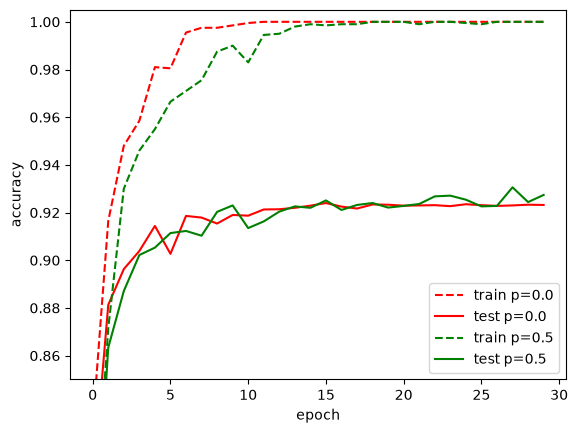

## 파트 3. `eval()` 을 깜빡하면

같은 시험 그림 10장을 두 번 예측해 본다.

In [ ]:
torch.manual_seed(0)
net = make_net(0.5)
_ = train(net, Xtr, ytr, Xte, yte, epochs=5)
first10 = Xte[:10]
net.train()                                               # forgot eval(): dropout still ON
with torch.no_grad():
    a, b = net(first10).argmax(1), net(first10).argmax(1)
print("train mode, run 1:", a.tolist()); print("train mode, run 2:", b.tolist())
net.eval()
with torch.no_grad():
    c, d = None, None  # TODO: predict twice in eval mode
print("eval mode,  run 1:", c.tolist()); print("eval mode,  run 2:", d.tolist()); print("true labels:      ", yte[:10].tolist())

**예상 결과**

```
train mode, run 1: [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]
train mode, run 2: [7, 2, 1, 0, 9, 1, 4, 4, 6, 9]
eval mode,  run 1: [7, 2, 1, 0, 4, 1, 4, 4, 5, 9]
eval mode,  run 2: [7, 2, 1, 0, 4, 1, 4, 4, 5, 9]
true labels:       [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]
```

**확인 질문**
1. 파트 1 의 평균이 원래 값과 같아야 하는 이유는? 1/(1−p) 배를 안 하면 어떻게 되나?
2. 파트 2 에서 드롭아웃이 있을 때 학습 곡선이 더 울퉁불퉁한 이유는?
3. 파트 2 에서 p = 0.2, 0.8 로도 해 보자. 슬라이드의 결과 (663, 680) 와 비슷한 경향인가?
4. 파트 3 에서 train 모드의 두 예측이 다른 이유를 한 문장으로.

데이터 출처: LeCun, Cortes, Burges, MNIST (torchvision) · Hinton et al. (2012) arXiv:1207.0580.